In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')
import matplotlib.pyplot as plt
import seaborn as sns

: 

# Загрузка данных

In [89]:
train_data = pd.read_csv('/kaggle/input/competitions/titanic/train.csv')
test_data = pd.read_csv('/kaggle/input/competitions/titanic/test.csv')

# EDA

In [5]:
train_data.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [6]:
train_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [7]:
print(train_data.isnull().sum())

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64


Признаки Age, Cabin, Embarked имеют пропуски. Нужно будет их как-то обработать

In [63]:
for col in ['Age', 'Cabin', 'Embarked']:
    print(f'\n{col}')
    print(train_data.groupby(train_data[col].isna())['Survived'].agg(['mean', 'count']))


Age
           mean  count
Age                   
False  0.406162    714
True   0.293785    177

Cabin
           mean  count
Cabin                 
False  0.666667    204
True   0.299854    687

Embarked
              mean  count
Embarked                 
False     0.382452    889
True      1.000000      2


Гипотеза об информативности пропусков: обнаружена связь между наличием пропусков в Age, Cabin и целевой переменной. Особенно сильная разница наблюдается для Cabin: 66.7% против 30.0%.

Идеи для ML: проверить добавление бинарных признаков AgeMissing и HasCabin. Для Embarked достаточно заполнить два пропуска наиболее частым значением в рамках baseline.

## Распределение классов

In [8]:
print(train_data['Survived'].value_counts())
print()
print(train_data['Survived'].value_counts()/train_data.shape[0])

Survived
0    549
1    342
Name: count, dtype: int64

Survived
0    0.616162
1    0.383838
Name: count, dtype: float64


Выживших в катастрофе не так много, всего 38% от датасета.

## Какие доступны фичи

Числовые фичи: Age, Fare, SibSp, Parch

Категориальные: Sex, Embarked

Порядковые: PClass

PassengerId, Name, Ticker, Cabin -- что это?

## Анализ фич

### пол

In [9]:
print(train_data['Sex'].value_counts() / train_data.shape[0])

Sex
male      0.647587
female    0.352413
Name: count, dtype: float64


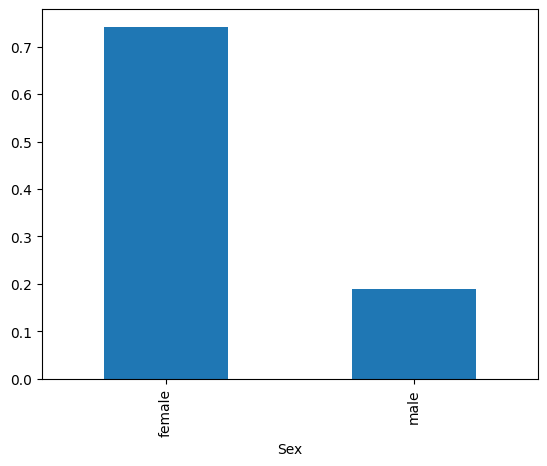

In [10]:
train_data.groupby('Sex')['Survived'].mean().plot.bar()
plt.show()

In [11]:
train_data.groupby('Sex')['Survived'].mean()

Sex
female    0.742038
male      0.188908
Name: Survived, dtype: float64

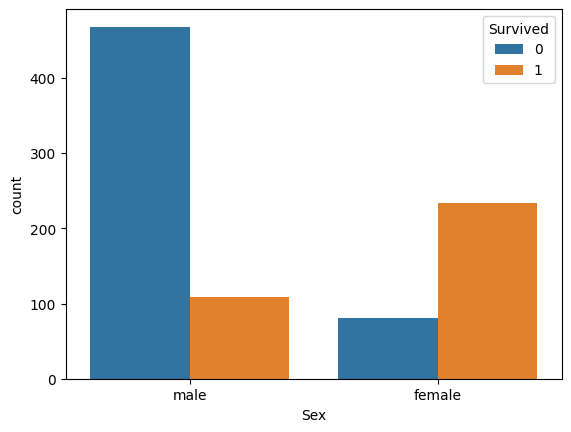

In [12]:
sns.countplot(x='Sex', hue='Survived', data=train_data)
plt.show()

1. Мужчин на корабле 65%, т.е. в 1.8 раз больше, чем женщин
2. Доля выживших среди мужчин составляет около 19% в том время как среди женщин почти 75%

Пол сильно влиял на выживаемость, так как в шлюпки сажали в первую очередь женщин и детей.

### Age

In [13]:
print(f"Самый старый пассажир: {train_data['Age'].max()} лет")
print(f"Самый молодой пассажира: {train_data['Age'].min()} лет")
print(f"Средний возраст: {train_data['Age'].mean():.1f} лет")

Самый старый пассажир: 80.0 лет
Самый молодой пассажира: 0.42 лет
Средний возраст: 29.7 лет


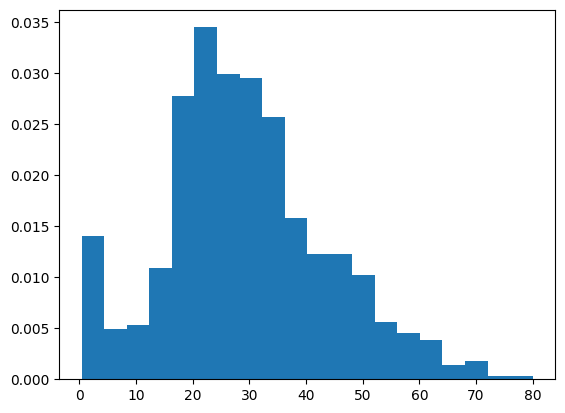

In [14]:
plt.hist(train_data['Age'], bins=20, density=True)
plt.show()

Преобладает возраст от 20 до 35 лет.
Интересный момент: в первом бине (примерно 0 - 4 года) есть всплеск плотности. На корабле было много младенцев?

### PClass

In [15]:
pd.crosstab(
    train_data.Pclass,
    train_data.Survived,
    normalize='index'
)

Survived,0,1
Pclass,,
1,0.370370,0.629630
2,0.527174,0.472826
3,0.757637,0.242363


В первом классе выжило 63%, во втором 47%, в третьем 24%. То есть чем более дорогой уровень класса, тем больше выживаемость.

### Embarked

In [55]:
train_data.groupby('Embarked')['Survived'].mean()

Embarked
C    0.553571
Q    0.389610
S    0.336957
Name: Survived, dtype: float64

Наибольший survival rate у тех, кто сел в Шербуре. Проверю, связано ли это с тем, что эти люди были преимущественно в первом классе.

C — Cherbourg (Шербур, Франция): выжило 55.4%.



Q — Queenstown (Квинстаун, Ирландия): выжило 39.0%.



S — Southampton (Саутгемптон, Англия): выжило 33.7%.

In [58]:
pd.crosstab(
    train_data['Embarked'],
    train_data['Pclass'],
    normalize='index'
)

Pclass,1,2,3
Embarked,,,
C,0.505952,0.101190,0.392857
Q,0.025974,0.038961,0.935065
S,0.197205,0.254658,0.548137


действительно, среди севших в Шербуре преобладают те, кто сел в первый класс.

## Проверка гипотез

Гипотезы:

H1: Выживаемость среди детей выше чем у взрослых. 
Можно зафиксировать порог например 12 лет и посмотреть распределение классов среди взрослых и детей.

H2: Выживаемость детей зависит от класса

H3: Дети выживали чаще взрослых внутри каждого класса

H4: Чем дороже билет, тем выше выживаемость.
Цена билета это Fare. Можно поделить на квантили и посмотреть survival rate в каждом из них.

H5: Пассажиры, путешествовавшие с семьей выживали с другой вероятностью чем одиночки. 

Есть признаки SibSp - супруги, братья, сестры на борту. Parch -- родители и дети. Можно объединить в один признак. И посмотреть survival rate среди тех, у кого он равен 0 и больше 0.

### H1: Выживаемость среди детей выше чем у взрослых. 

In [30]:
df = train_data.dropna(subset=['Age']).copy()
df['IsChild'] =  df['Age'] <= 12

In [27]:
adults = df[df['Age'] > 12]
children = df[df['Age'] <= 12]

In [31]:
print(f"Выживших среди взрослых: {df[df['IsChild'] == 0]['Survived'].mean():.2f}")
print(f"Выживших среди детей: {df[df['IsChild'] == 1]['Survived'].mean():.2f}")

Выживших среди взрослых: 0.39
Выживших среди детей: 0.58


да, действительно, выживаемость выше у детей

In [29]:
pd.crosstab(
    df['IsChild'],
    df['Pclass'],
    normalize='index'
)

Pclass,1,2,3
IsChild,,,
False,0.282171,0.241860,0.475969
True,0.057971,0.246377,0.695652


Интересная особенность, что доля детей больше всего в третьем классе. И что в первом классе детей мало (5%)

### H2: Выживаемость детей зависит от класса

In [34]:
df[df['IsChild']].groupby('Pclass')['Survived'].agg(
    ['count', 'sum', 'mean']
)

,count,sum,mean
Pclass,,,
1,4,3,0.750000
2,17,17,1.000000
3,48,20,0.416667


Действительно, в классах 1 и 2 выживаемость детей выше, чем в третьем классе. Причем во втором она стопроцентная. А в первом ниже чем во втором, тоже интересно

### H3: Дети выживали чаще взрослых внутри каждого класса

In [33]:
df.groupby(['Pclass', 'IsChild'])['Survived'].agg(['mean', 'count'])

mean  count
Pclass IsChild                 
1      False    0.653846    182
       True     0.750000      4
2      False    0.423077    156
       True     1.000000     17
3      False    0.211726    307
       True     0.416667     48

да, это так

Идея: добавить отдельный признак IsChild

### H4: Чем дороже билет, тем выше выживаемость.

In [42]:
train_data['Fare quantile'] = pd.qcut(train_data['Fare'], q=4)

In [43]:
train_data.groupby('Fare quantile', observed=True)['Survived'].agg(['mean', 'count'])

,mean,count
Fare quantile,,
"(-0.001, 7.91]",0.197309,223
"(7.91, 14.454]",0.303571,224
"(14.454, 31.0]",0.454955,222
"(31.0, 512.329]",0.581081,222


да, виден рост выживаемости с ростом цены билета.

Вывод: использовать Fare в бейзлайне

### H5: Пассажиры, путешествовавшие с семьей выживали с другой вероятностью чем одиночки.

In [44]:
train_data['FamilySize'] = train_data['SibSp'] + train_data['Parch'] + 1 # 1 значит включаем самого пассажира

In [47]:
print(f"Выживших среди одиночек: {train_data[train_data['FamilySize'] == 1]['Survived'].mean():.2f}")
print(f"Выживших среди тех, у кого были члены семьи на корабле: {train_data[train_data['FamilySize'] > 1]['Survived'].mean():.2f}")

Выживших среди одиночек: 0.30
Выживших среди тех, у кого были члены семьи на корабле: 0.51


Гипотеза подтверждается

Исследую зависимость выживаемости от числа членов семьи

In [53]:
family_stats = train_data.groupby('FamilySize')['Survived'].agg(['mean', 'count'])
family_stats 

,mean,count
FamilySize,,
1,0.303538,537
2,0.552795,161
3,0.578431,102
4,0.724138,29
5,0.200000,15
6,0.136364,22
7,0.333333,12
8,0.000000,6
11,0.000000,7


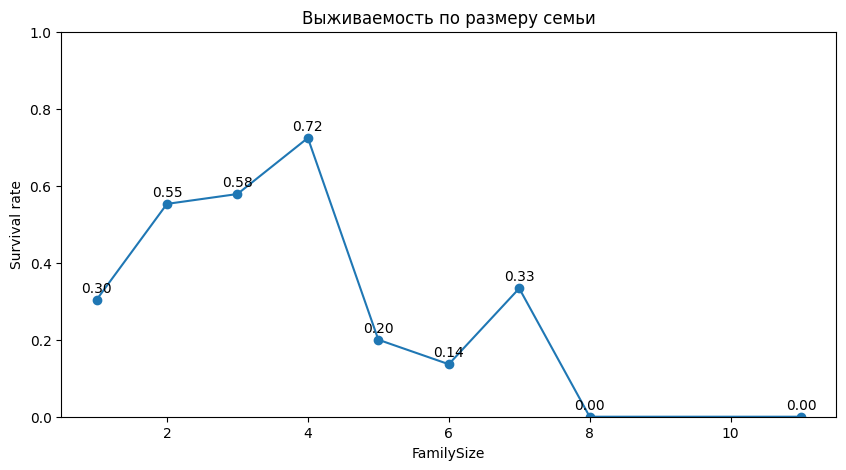

In [54]:
plt.figure(figsize=(10, 5))
plt.plot(family_stats.index, family_stats['mean'], marker='o')
plt.xlabel('FamilySize')
plt.ylabel('Survival rate')
plt.title('Выживаемость по размеру семьи')
plt.ylim(0, 1)

for x, y in zip(family_stats.index, family_stats['mean']):
    plt.text(x, y + 0.02, f'{y:.2f}', ha='center')

plt.show()

Размер семьи немонотонно влияет на выживаемость. От 1 до 4 членов семьи выживаемость растет, а дальше падает.

Идея: сделать признак со значениями 0 (одиночка), от 1 до 4 (имеет небольшую семью), больше 5 (имеет большую семью)

In [57]:
train_data.columns

Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked', 'Fare quantile',
       'FamilySize'],
      dtype='object')

## Корреляции

<Axes: >

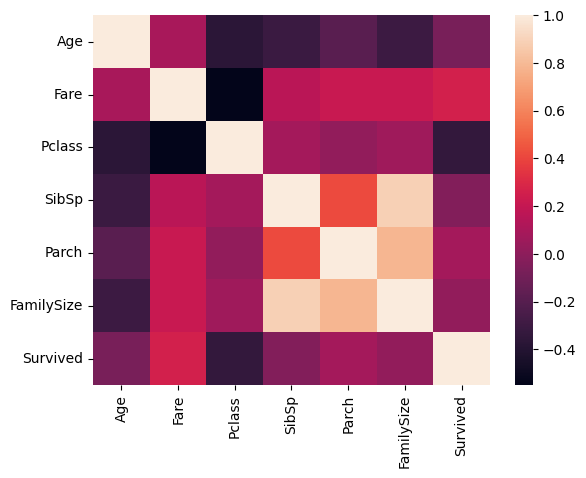

In [61]:
features = [
    'Age', 'Fare', 'Pclass',
    'SibSp', 'Parch', 'FamilySize',
    'Survived'
]

sns.heatmap(train_data[features].corr())